# Módulo 4 — Cálculo estocástico: movimento browniano, Itô e Girsanov

## Introdução

Para levar a teoria do Capítulo 3 ao tempo contínuo, é preciso uma matemática própria para trajetórias aleatórias que não são suaves. O **movimento browniano** é o modelo básico desse tipo de trajetória: contínuo, mas com oscilações em qualquer escala de tempo, a ponto de não ter derivada em ponto algum.

Essa irregularidade muda as regras do cálculo. Uma integral em relação ao movimento browniano, a **integral de Itô**, depende de onde se avalia o integrando em cada intervalo, e a escolha financeiramente correta, decidir a posição antes de conhecer o movimento seguinte, faz da integral um martingal. A regra da cadeia também muda: a **fórmula de Itô** ganha um termo de segunda ordem, porque o quadrado de um incremento browniano não é desprezível. É desse termo que vem o $-\tfrac12\sigma^2$ que aparece em toda a teoria de opções.

A terceira peça é o **teorema de Girsanov**, que mostra como trocar a medida de probabilidade alterando apenas a deriva do processo. É ele que transforma a dinâmica observada de um ativo na dinâmica neutra ao risco usada para precificar. O capítulo apresenta as três ferramentas com simulações que as tornam concretas: o leitor vê a variação quadrática convergir, a correção de Itô aparecer na média e a mudança de medida reponderar trajetórias.

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** seção 4.5 do livro e o lema de Itô das seções 5.6.1 e 9.7.1.

## O que você vai conseguir fazer ao final

1. Explicar o que é um movimento browniano e por que ele não tem derivada.
2. Entender por que a integral estocástica depende do ponto de avaliação, e por que se usa o de Itô.
3. Aplicar o lema de Itô, sabendo de onde vem o termo extra.
4. Trocar de medida com o teorema de Girsanov e conectar isso à derivada de Radon-Nikodym do Módulo 3.
5. Mostrar por que $\mu$ desaparece do preço de uma opção, agora em tempo contínuo.
6. Explicar por que estratégias precisam de uma condição de admissibilidade.
7. Dizer quando um modelo contínuo é completo, e o que muda com volatilidade estocástica.

## Como este módulo se relaciona com o livro

O livro enuncia os resultados de tempo contínuo em alto nível e remete às referências, e **não trata do teorema de Girsanov**. Aqui construímos os mesmos resultados de forma intuitiva, partindo do mundo discreto do Módulo 3 e **conferindo cada passo numericamente**. A abordagem é heurística no rigor, mas correta nos resultados; para as demonstrações completas, veja Björk (2004) ou Shreve (2004).

## 0. Preparação

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, kurtosis
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def bsm_call(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d1 - sigma * np.sqrt(T))


print("Ambiente pronto.")

Ambiente pronto.


---
## 1. Do passeio aleatório ao movimento browniano

**Livro: §4.5, Definição 33**

### 1.1 A escala correta

Comece com o jogo justo do Módulo 3: em cada passo, sobe ou desce com chances iguais. Queremos encurtar os passos, **mantendo uma variância finita**. Para $n$ passos em $[0, 1]$, com duração $\Delta t = 1/n$ e tamanho $a$:

$$\text{Var}\Big(\sum_{i=1}^{n} X_i\Big) = n\,a^2.$$

Para essa variância valer $t = 1$, é preciso $a = \sqrt{\Delta t}$. Esse é o coração de tudo o que vem:

$$\boxed{\text{um movimento de duração } \Delta t \text{ tem tamanho } \sqrt{\Delta t}.}$$

Como $\sqrt{\Delta t} \gg \Delta t$ para $\Delta t$ pequeno, o movimento aleatório domina a tendência em escalas curtas.

Pelo teorema central do limite, a soma tende à normal. A versão para trajetórias inteiras é o **teorema de Donsker**: o passeio aleatório reescalado converge para um processo contínuo, o movimento browniano.

### 1.2 Definição

Um **movimento browniano padrão** $(Z_t)$ é um processo adaptado que satisfaz:

1. $Z_0 = 0$;
2. o incremento $Z_t - Z_s$ é independente de $\mathcal{F}_s$, para $s < t$ (o futuro não depende do passado);
3. $Z_t - Z_s \sim N(0, t-s)$;
4. as trajetórias são contínuas.

### Laboratório 1.1 — A convergência

A soma de $n$ passos $\pm\sqrt{1/n}$ pode ser amostrada diretamente pela distribuição binomial. Para um passeio de $n$ passos, a teoria dá curtose em excesso igual a $-2/n$.

,Passos n,Variância,Curtose em excesso,Teoria: −2/n,P(W ≤ 1)
0,1,"1,000","-2,000","-2,000","1,000"
1,4,"1,000","-0,501","-0,500","0,938"
2,16,"0,998","-0,122","-0,125","0,895"
3,64,"1,001","-0,031","-0,031","0,869"
4,1024,"0,999","-0,006","-0,002","0,849"
5,65536,"0,999","0,004","-0,000","0,843"


Φ(1) = 0,841
OK — com passo √Δt, a variância é 1 em qualquer n
OK — a curtose do passeio segue −2/n
OK — para n grande, a distribuição é a normal


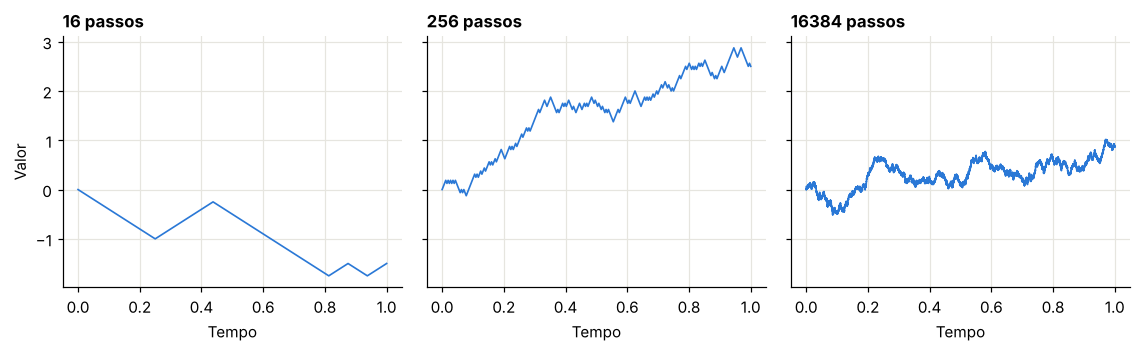

In [2]:
rng = np.random.default_rng(501)
linhas = []
for n in [1, 4, 16, 64, 1024, 65536]:
    W = (2 * rng.binomial(n, 0.5, 2_000_000) - n) / np.sqrt(n)
    linhas.append({"Passos n": n, "Variância": W.var(), "Curtose em excesso": float(kurtosis(W)), "Teoria: −2/n": -2 / n, "P(W ≤ 1)": (W <= 1 + 1e-12).mean()})
df = pd.DataFrame(linhas)
tabela(df)
print("Φ(1) =", f3(norm.cdf(1)))
ok(np.allclose(df["Variância"], 1, atol=0.005), "com passo √Δt, a variância é 1 em qualquer n")
ok(np.allclose(df["Curtose em excesso"], df["Teoria: −2/n"], atol=0.02), "a curtose do passeio segue −2/n")
ok(abs(df["P(W ≤ 1)"].iloc[-1] - norm.cdf(1)) < 0.003, "para n grande, a distribuição é a normal")

rng = np.random.default_rng(502)
fig, eixos = plt.subplots(1, 3, figsize=(10.5, 3.3), sharey=True)
for ax, n in zip(eixos, [16, 256, 16384]):
    passos = rng.choice([-1.0, 1.0], size=n) * np.sqrt(1 / n)
    ax.plot(np.linspace(0, 1, n + 1), np.r_[0.0, np.cumsum(passos)], color=AZUL, lw=1.1)
    ax.set_title(f"{n} passos")
    ax.set_xlabel("Tempo")
eixos[0].set_ylabel("Valor")
plt.tight_layout()
plt.show()

---
## 2. As propriedades estranhas do browniano

### 2.1 Martingale

Se $s < t$, usando a independência dos incrementos:

$$\mathbb{E}_s[Z_t] = \mathbb{E}_s[Z_s + (Z_t - Z_s)] = Z_s + 0 = Z_s.$$

Outro martingale importante é $Z_t^2 - t$. De fato, escrevendo $Z_t = Z_s + \Delta$:

$$\mathbb{E}_s[Z_t^2] = Z_s^2 + 2 Z_s\,\mathbb{E}_s[\Delta] + \mathbb{E}_s[\Delta^2] = Z_s^2 + (t-s).$$

Subtraindo $t$ dos dois lados, resulta $\mathbb{E}_s[Z_t^2 - t] = Z_s^2 - s$.

### 2.2 Covariância

Para $s \le t$: $\ \mathbb{E}[Z_s Z_t] = \mathbb{E}[Z_s(Z_s + \Delta)] = \mathbb{E}[Z_s^2] + 0 = s$. Logo, $\text{Cov}(Z_s, Z_t) = \min(s, t)$.

### 2.3 Variação total infinita

Particione $[0,T]$ em $n$ intervalos de tamanho $\Delta t$. A soma dos valores absolutos tem esperança

$$\mathbb{E}\sum_i |\Delta Z_i| = n\,\sqrt{\Delta t}\,\sqrt{2/\pi} = \sqrt{\frac{2Tn}{\pi}} \xrightarrow[n\to\infty]{} \infty.$$

Em palavras: a distância percorrida pelo browniano em qualquer intervalo é infinita. Por isso, $Z$ **não é derivável em lugar nenhum** e não se pode escrever a integral $\int H\,dZ$ como uma integral ordinária.

### 2.4 Variação quadrática finita

Agora eleve ao quadrado:

$$Q_n = \sum_i (\Delta Z_i)^2.$$

Cada termo tem média $\Delta t$ e variância $2\Delta t^2$. Somando $n$ termos independentes:

$$\mathbb{E}[Q_n] = n\Delta t = T, \qquad \text{Var}(Q_n) = 2n\Delta t^2 = \frac{2T^2}{n} \to 0.$$

A variância vai a zero, então $Q_n$ deixa de ser aleatório: converge para o **número** $T$. É a principal surpresa do cálculo estocástico e é escrita como

$$\boxed{(dZ_t)^2 = dt.}$$

Uma função suave faz o oposto: variação total finita e variação quadrática zero.

### Laboratório 2.1 — Propriedades e variação

,Grandeza,Simulado,Teoria
0,"Cov(Z(0,25), Z(0,75))","0,251","0,250"
1,Corr de incrementos disjuntos,"0,002","0,000"
2,E[Z(1)² − 1],"0,000","0,000"
3,"E[(Z(1)²−1) | Z(0,75)>0] − E[(Z(0,75)²−0,75) |...","0,001","0,000"


OK — Cov(Z_s, Z_t) = min(s, t)
OK — incrementos disjuntos são não correlacionados
OK — Z² − t é martingale, inclusive condicionado ao passado


,n,VT browniano,Teoria √(2n/π),VQ browniano,VT seno,VQ seno
0,16,"3,523","3,192","1,012","4,000","1,218"
1,256,"13,441","12,766","1,052","4,000","0,077"
2,4096,"51,247","51,065","1,024","4,000","0,005"
3,65536,"204,107","204,258","1,002","4,000","0,000"
4,1048576,"816,699","817,034","0,999","4,000","0,000"
5,4194304,"1.633,949","1.634,068","1,000","4,000","0,000"


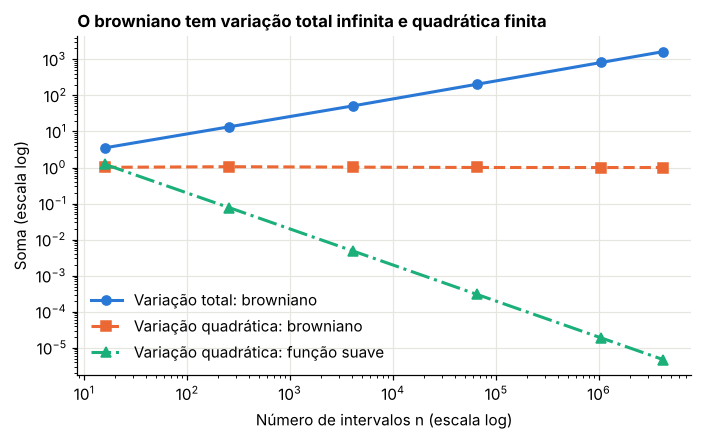

OK — a variação total cresce como √(2n/π)
OK — a variação quadrática converge para T = 1
OK — em função suave, a variação quadrática some


In [3]:
rng = np.random.default_rng(503)
M_, I_ = 100, 200_000
dZ = np.sqrt(1 / M_) * rng.standard_normal((M_, I_))
Z = np.cumsum(dZ, axis=0)
t25, t75 = 24, 74

tabela(pd.DataFrame([
    {"Grandeza": "Cov(Z(0,25), Z(0,75))", "Simulado": float(np.mean(Z[t25] * Z[t75])), "Teoria": 0.25},
    {"Grandeza": "Corr de incrementos disjuntos", "Simulado": float(np.corrcoef(Z[t25], Z[t75] - Z[t25])[0, 1]), "Teoria": 0.0},
    {"Grandeza": "E[Z(1)² − 1]", "Simulado": float(np.mean(Z[-1] ** 2 - 1)), "Teoria": 0.0},
    {"Grandeza": "E[(Z(1)²−1) | Z(0,75)>0] − E[(Z(0,75)²−0,75) | Z(0,75)>0]", "Simulado": float(np.mean((Z[-1] ** 2 - 1)[Z[t75] > 0]) - np.mean((Z[t75] ** 2 - 0.75)[Z[t75] > 0])), "Teoria": 0.0},
]))
ok(abs(np.mean(Z[t25] * Z[t75]) - 0.25) < 0.005, "Cov(Z_s, Z_t) = min(s, t)")
ok(abs(np.corrcoef(Z[t25], Z[t75] - Z[t25])[0, 1]) < 0.01, "incrementos disjuntos são não correlacionados")
ok(abs(np.mean((Z[-1] ** 2 - 1)[Z[t75] > 0]) - np.mean((Z[t75] ** 2 - 0.75)[Z[t75] > 0])) < 0.015, "Z² − t é martingale, inclusive condicionado ao passado")
del Z, dZ

rng = np.random.default_rng(504)
K_max = 22
n_fino = 2**K_max
incr = np.sqrt(1 / n_fino) * rng.standard_normal(n_fino)
trajeto = np.r_[0.0, np.cumsum(incr)]
grade_fina = np.linspace(0, 1, n_fino + 1)
suave = np.sin(2 * np.pi * grade_fina)

linhas = []
for k in [4, 8, 12, 16, 20, 22]:
    p = 2 ** (K_max - k)
    z = trajeto[::p]
    s = suave[::p]
    n = 2**k
    linhas.append({"n": n, "VT browniano": float(np.abs(np.diff(z)).sum()), "Teoria √(2n/π)": float(np.sqrt(2 * n / np.pi)), "VQ browniano": float((np.diff(z) ** 2).sum()), "VT seno": float(np.abs(np.diff(s)).sum()), "VQ seno": float((np.diff(s) ** 2).sum())})
var = pd.DataFrame(linhas)
tabela(var)

fig, ax = plt.subplots()
ax.loglog(var["n"], var["VT browniano"], color=AZUL, marker="o", markersize=6, label="Variação total: browniano")
ax.loglog(var["n"], var["VQ browniano"], color=LARANJA, marker="s", markersize=6, ls="--", label="Variação quadrática: browniano")
ax.loglog(var["n"], var["VQ seno"], color=VERDE, marker="^", markersize=6, ls="-.", label="Variação quadrática: função suave")
ax.set_title("O browniano tem variação total infinita e quadrática finita")
ax.set_xlabel("Número de intervalos n (escala log)")
ax.set_ylabel("Soma (escala log)")
ax.legend()
plt.show()

ult = var.iloc[-1]
ok(abs(ult["VT browniano"] / ult["Teoria √(2n/π)"] - 1) < 0.01, "a variação total cresce como √(2n/π)")
ok(abs(ult["VQ browniano"] - 1) < 0.01, "a variação quadrática converge para T = 1")
ok(ult["VQ seno"] < 1e-4 and abs(ult["VT seno"] - 4) < 1e-3, "em função suave, a variação quadrática some")

---
## 3. A integral de Itô

**Livro: §4.5, definições 28 a 31**

### 3.1 O problema

Queremos dar sentido ao ganho de uma estratégia, $\int_0^T H_s\,dZ_s$, o análogo contínuo de $G_t$ no Módulo 3. Tentamos o limite de somas:

$$\sum_i H(\tau_i)\,(Z_{t_{i+1}} - Z_{t_i}), \qquad \tau_i \in [t_i, t_{i+1}].$$

Numa integral ordinária, a escolha de $\tau_i$ não importa. Aqui importa muito. Veja com $H = Z$ e denote $a = Z_{t_i}$, $b = Z_{t_{i+1}}$. Usando duas identidades algébricas:

$$a(b - a) = \tfrac12\big[(b^2 - a^2) - (b-a)^2\big], \qquad b(b - a) = \tfrac12\big[(b^2 - a^2) + (b-a)^2\big].$$

Somando no tempo, os termos $b^2 - a^2$ telescopam, e os termos $(b-a)^2$ dão a variação quadrática:

- **Ponto esquerdo:** $\sum a(b-a) \to \tfrac12 Z_T^2 - \tfrac12 T$.
- **Ponto direito:** $\sum b(b-a) \to \tfrac12 Z_T^2 + \tfrac12 T$.
- **Ponto médio** (Stratonovich): $\to \tfrac12 Z_T^2$.

A diferença é exatamente a variação quadrática, que seria zero num mundo suave.

### 3.2 Por que usar o ponto esquerdo

Porque é o único coerente com a negociação: você decide a posição **antes** do movimento. É exatamente a condição de previsibilidade do Módulo 3. A integral de Itô com integrando previsível é o ganho de uma estratégia factível, e herda a propriedade central:

$$\mathbb{E}\Big[\int_0^T H_s\,dZ_s\Big] = 0.$$

O livro constrói a integral com as **estratégias simples previsíveis**: posições constantes entre datas. A integral geral é o limite delas.

### 3.3 Isometria de Itô

Para $H$ previsível e quadrado-integrável:

$$\mathbb{E}\Big[\Big(\int_0^T H_s\,dZ_s\Big)^2\Big] = \mathbb{E}\Big[\int_0^T H_s^2\,ds\Big].$$

**A prova na forma simples.** Abrindo o quadrado de $\sum_i H_i\Delta Z_i$:

- Termos cruzados, $i < j$: $\mathbb{E}[H_i\Delta Z_i H_j\Delta Z_j] = \mathbb{E}\big[H_i\Delta Z_i H_j\,\mathbb{E}_{t_j}[\Delta Z_j]\big] = 0$.
- Termos quadrados: $\mathbb{E}[H_i^2\Delta Z_i^2] = \mathbb{E}\big[H_i^2\,\mathbb{E}_{t_i}[\Delta Z_i^2]\big] = \mathbb{E}[H_i^2]\Delta t$.

Note que os dois passos usam $H_i$ previsível.

### Laboratório 3.1 — O ponto de avaliação muda o resultado

In [4]:
rng = np.random.default_rng(505)
n, paths = 4096, 2000
meio = np.sqrt(1 / (2 * n)) * rng.standard_normal((2 * n, paths))
Zf = np.vstack([np.zeros(paths), np.cumsum(meio, axis=0)])
inc = Zf[2::2] - Zf[:-2:2]

somas = {
    "Esquerdo (Itô)": ((Zf[:-2:2] * inc).sum(axis=0), 0.5 * Zf[-1] ** 2 - 0.5),
    "Médio (Stratonovich)": ((Zf[1::2] * inc).sum(axis=0), 0.5 * Zf[-1] ** 2),
    "Direito": ((Zf[2::2] * inc).sum(axis=0), 0.5 * Zf[-1] ** 2 + 0.5),
}
linhas = []
for nome, (soma, limite) in somas.items():
    linhas.append({"Ponto de avaliação": nome, "Média da soma": float(soma.mean()), "Raiz do erro quadrático contra o limite": float(np.sqrt(np.mean((soma - limite) ** 2)))})
res = pd.DataFrame(linhas).set_index("Ponto de avaliação")
tabela(res.reset_index())
ok(all(res["Raiz do erro quadrático contra o limite"] < 0.03), "as três somas convergem para seus limites teóricos")
ok(abs(res.loc["Esquerdo (Itô)", "Média da soma"]) < 0.07, "só a integral de Itô tem média zero")
ok(res.loc["Direito", "Média da soma"] > 0.9, "o ponto direito espia o futuro e tem média T")
del Zf, meio, inc

,Ponto de avaliação,Média da soma,Raiz do erro quadrático contra o limite
0,Esquerdo (Itô),"-0,004","0,011"
1,Médio (Stratonovich),"0,497","0,008"
2,Direito,"0,997","0,011"


OK — as três somas convergem para seus limites teóricos
OK — só a integral de Itô tem média zero
OK — o ponto direito espia o futuro e tem média T


### Laboratório 3.2 — A isometria

Para $H = Z$: $\mathbb{E}\int_0^1 Z_s^2\,ds = \int_0^1 s\,ds = \tfrac12$.

In [5]:
rng = np.random.default_rng(506)
n, paths = 250, 300_000
dt = 1 / n
Z, integral, energia = np.zeros(paths), np.zeros(paths), np.zeros(paths)
for _ in range(n):
    d = np.sqrt(dt) * rng.standard_normal(paths)
    integral += Z * d
    energia += Z**2 * dt
    Z += d
tabela(pd.DataFrame([
    {"Grandeza": "E[∫Z dZ]", "Simulado": float(integral.mean()), "Teoria": 0.0},
    {"Grandeza": "E[(∫Z dZ)²]", "Simulado": float((integral**2).mean()), "Teoria": 0.5 * (1 - 1 / n)},
    {"Grandeza": "E[∫Z² ds]", "Simulado": float(energia.mean()), "Teoria": 0.5 * (1 - 1 / n)},
]))
ok(abs((integral**2).mean() - energia.mean()) < 0.01, "isometria de Itô")
ok(abs(integral.mean()) < 0.005, "a integral de Itô tem média zero")

,Grandeza,Simulado,Teoria
0,E[∫Z dZ],"-0,000","0,000"
1,E[(∫Z dZ)²],"0,496","0,498"
2,E[∫Z² ds],"0,498","0,498"


OK — isometria de Itô
OK — a integral de Itô tem média zero


### 3.4 Quando "martingale" falha: as estratégias de dobrar

A integral de Itô com integrando sem controle é apenas um **martingale local**, e isso permite uma construção perturbadora. Considere

$$X_t = \int_0^t \frac{dZ_s}{\sqrt{1 - s}}, \qquad t < 1.$$

Sua variância é $\int_0^t \frac{ds}{1-s} = -\ln(1-t)$, que tende a infinito quando $t \to 1$. $X$ se comporta como um browniano num relógio acelerado, $s = -\ln(1-t)$. Um browniano atinge qualquer nível, cedo ou tarde, com probabilidade 1. Logo:

**Comece com zero e pare ao atingir $+1$: antes de $t = 1$, você terá ganho 1 com certeza.**

É o análogo contínuo da estratégia de dobrar a aposta. O problema está no caminho: o valor pode cair arbitrariamente antes de voltar. Isso exige crédito ilimitado.

A solução é restringir o conjunto de estratégias. **Admissível** (Def. 35 do livro) significa que o valor nunca cai abaixo de um limite $-\alpha$. Com esse limite, a estratégia para em $+1$ ou em $-\alpha$. Pelo teorema de parada de martingales, $\mathbb{E}[\text{ganho}] = 0$, ou seja,

$$1\cdot P(+1) - \alpha\,(1 - P(+1)) = 0 \quad\Rightarrow\quad P(+1) = \frac{\alpha}{1+\alpha}.$$

O almoço grátis desaparece.

### Laboratório 3.3 — Limites de crédito

Primeiro, a probabilidade de já ter alcançado $+1$ em cada data, sem limite. Pelo princípio da reflexão, para um browniano no relógio $s$: $P(\max \ge 1) = 2\big(1 - \Phi(1/\sqrt{s})\big)$. Depois, a simulação com limite de crédito.

In [6]:
linhas = []
for rotulo, falta in [("0,500", 0.5), ("0,100", 0.1), ("0,001", 1e-3), ("10⁻⁹", 1e-9), ("10⁻³⁰", 1e-30)]:
    s = -np.log(falta)
    linhas.append({"Tempo restante 1 − t": rotulo, "Relógio s": float(s), "P(atingiu +1 até t)": float(2 * (1 - norm.cdf(1 / np.sqrt(s))))})
tabela(pd.DataFrame(linhas))

rng = np.random.default_rng(507)
ds = 0.002
linhas = []
for alfa in [1.0, 3.0, 9.0]:
    n = 40_000
    x = np.zeros(n)
    ativo = np.arange(n)
    ganho = np.zeros(n)
    while ativo.size:
        x[ativo] += np.sqrt(ds) * rng.standard_normal(ativo.size)
        cima, baixo = x[ativo] >= 1, x[ativo] <= -alfa
        ganho[ativo[cima]], ganho[ativo[baixo]] = 1.0, -alfa
        ativo = ativo[~(cima | baixo)]
    linhas.append({"Limite de crédito α": alfa, "P(+1): simulada": float((ganho > 0).mean()), "P(+1): teoria α/(1+α)": alfa / (1 + alfa), "Ganho médio": float(ganho.mean()), "Erro-padrão": float(ganho.std(ddof=1) / np.sqrt(n))})
lim = pd.DataFrame(linhas)
tabela(lim)
ok(np.allclose(lim["P(+1): simulada"], lim["P(+1): teoria α/(1+α)"], atol=0.012), "com limite de crédito, P(+1) = α/(1+α)")
ok((lim["Ganho médio"].abs() < 4 * lim["Erro-padrão"] + 0.02).all(), "com limite de crédito, o ganho médio é zero")

,Tempo restante 1 − t,Relógio s,P(atingiu +1 até t)
0,"0,500","0,693","0,230"
1,"0,100","2,303","0,510"
2,"0,001","6,908","0,704"
3,10⁻⁹,"20,723","0,826"
4,10⁻³⁰,"69,078","0,904"


,Limite de crédito α,P(+1): simulada,P(+1): teoria α/(1+α),Ganho médio,Erro-padrão
0,"1,000","0,502","0,500","0,003","0,005"
1,"3,000","0,747","0,750","-0,014","0,009"
2,"9,000","0,898","0,900","-0,022","0,015"


OK — com limite de crédito, P(+1) = α/(1+α)
OK — com limite de crédito, o ganho médio é zero


---
## 4. O lema de Itô

**Livro: §5.6.1 e §9.7.1**

### 4.1 De onde vem

Seja $f(S, t)$ suave e $dS_t = m_t\,dt + v_t\,dZ_t$. A expansão de Taylor de segunda ordem é

$$df = \frac{\partial f}{\partial t}dt + \frac{\partial f}{\partial S}dS + \frac12\frac{\partial^2 f}{\partial S^2}(dS)^2 + \dots$$

Calculamos $(dS)^2 = m^2\,dt^2 + 2mv\,dt\,dZ + v^2\,(dZ)^2$. Usamos as **regras de multiplicação**, que resumem a Seção 2:

| $\times$ | $dt$ | $dZ$ |
|---|---|---|
| $dt$ | 0 | 0 |
| $dZ$ | 0 | $dt$ |

Por ordem de grandeza: $dt^2$ e $dt\,dZ \sim dt^{3/2}$ são desprezíveis; $(dZ)^2 = dt$ não. Sobra $(dS)^2 = v^2\,dt$, e resulta o **lema de Itô**:

$$\boxed{df = \Big(\frac{\partial f}{\partial t} + m\frac{\partial f}{\partial S} + \frac12 v^2\frac{\partial^2 f}{\partial S^2}\Big)dt + v\frac{\partial f}{\partial S}\,dZ.}$$

No cálculo comum, o termo de segunda ordem desaparece. Aqui, como $(dZ)^2$ tem ordem $dt$, ele **sobrevive**. Esse é o único ingrediente novo.

### 4.2 Exemplo 1: $f = Z^2$

Com $m = 0$, $v = 1$, $f' = 2Z$, $f'' = 2$:

$$d(Z^2) = 2Z\,dZ + dt \quad\Longrightarrow\quad \int_0^T Z\,dZ = \tfrac12 Z_T^2 - \tfrac12 T.$$

Foi o resultado que obtivemos da soma à esquerda.

### 4.3 Exemplo 2: resolver o browniano geométrico

Seja $dS = \mu S\,dt + \sigma S\,dZ$. Aplicamos Itô a $f = \ln S$, com $f' = 1/S$, $f'' = -1/S^2$, $m = \mu S$, $v = \sigma S$:

$$d\ln S = \Big(\mu S\cdot\frac{1}{S} - \frac12\sigma^2S^2\cdot\frac{1}{S^2}\Big)dt + \sigma S\cdot\frac{1}{S}\,dZ = \big(\mu - \tfrac12\sigma^2\big)dt + \sigma\,dZ.$$

O lado direito não tem $S$, então a integração é imediata:

$$S_T = S_0\exp\Big[\big(\mu - \tfrac12\sigma^2\big)T + \sigma Z_T\Big].$$

Fica enfim justificado o termo $-\tfrac12\sigma^2$ que usamos como caixa-preta desde o Módulo 1. Ele é o **termo de Itô**.

### 4.4 Versão multidimensional

Com vários processos, as regras ganham $dZ^1 dZ^2 = \rho\,dt$, e surgem termos cruzados. Para $f(X,Y)$:

$$df = f_X\,dX + f_Y\,dY + \tfrac12 f_{XX}(dX)^2 + \tfrac12 f_{YY}(dY)^2 + f_{XY}\,dX\,dY.$$

O caso $f = XY$ é a **regra do produto**: $d(XY) = X\,dY + Y\,dX + dX\,dY$.

Por que vale a atenção: a dinâmica do modelo geral (BCC97) tem índice, variância e juros simultaneamente, e no Módulo 11 precisaremos exatamente dessa versão.

### Laboratório 4.1 — Conferindo o lema trajetória a trajetória

Com $f(z) = e^z$, temos $f' = f'' = e^z$. Comparamos três quantidades **em cada trajetória**: $f(Z_T) - f(0)$, a soma de Itô com correção e a soma sem correção.

,n,Erro com o termo de Itô,Erro sem o termo de Itô
0,32,"0,202","0,797"
1,128,"0,102","0,801"
2,512,"0,052","0,796"
3,2048,"0,029","0,792"
4,8192,"0,014","0,794"
5,32768,"0,007","0,793"


Inclinação log-log do erro com correção: -0,483


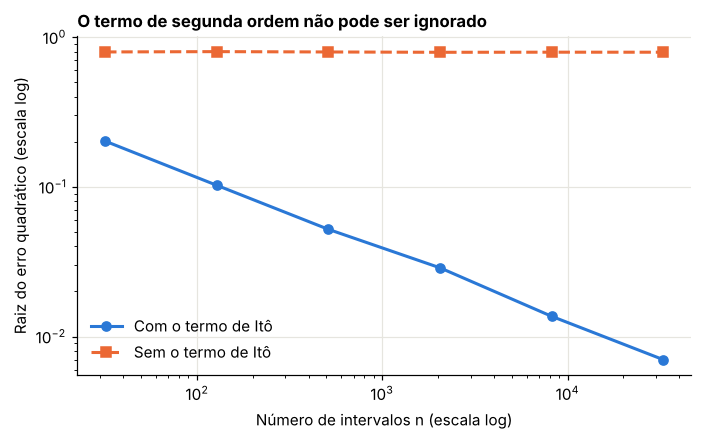

OK — com o termo de Itô, o erro cai como 1/√n
OK — sem o termo de Itô, o erro não some


In [7]:
rng = np.random.default_rng(508)
n_max, paths = 2**15, 1000
base = np.sqrt(1 / n_max) * rng.standard_normal((n_max, paths))
Z_ = np.vstack([np.zeros(paths), np.cumsum(base, axis=0)])

linhas = []
for n in [2**k for k in (5, 7, 9, 11, 13, 15)]:
    p = n_max // n
    z = Z_[::p]
    dz = np.diff(z, axis=0)
    fl = np.exp(z[:-1])
    com = (fl * dz).sum(axis=0) + 0.5 * fl.sum(axis=0) / n
    sem = (fl * dz).sum(axis=0)
    alvo = np.exp(z[-1]) - 1
    linhas.append({"n": n, "Erro com o termo de Itô": float(np.sqrt(np.mean((com - alvo) ** 2))), "Erro sem o termo de Itô": float(np.sqrt(np.mean((sem - alvo) ** 2)))})
ito = pd.DataFrame(linhas)
tabela(ito)
incl = np.polyfit(np.log(ito["n"]), np.log(ito["Erro com o termo de Itô"]), 1)[0]
print("Inclinação log-log do erro com correção:", f3(incl))

fig, ax = plt.subplots()
ax.loglog(ito["n"], ito["Erro com o termo de Itô"], color=AZUL, marker="o", markersize=6, label="Com o termo de Itô")
ax.loglog(ito["n"], ito["Erro sem o termo de Itô"], color=LARANJA, marker="s", markersize=6, ls="--", label="Sem o termo de Itô")
ax.set_title("O termo de segunda ordem não pode ser ignorado")
ax.set_xlabel("Número de intervalos n (escala log)")
ax.set_ylabel("Raiz do erro quadrático (escala log)")
ax.legend()
plt.show()

ok(-0.6 < incl < -0.4, "com o termo de Itô, o erro cai como 1/√n")
ok(ito["Erro sem o termo de Itô"].iloc[-1] > 0.5, "sem o termo de Itô, o erro não some")
del base, Z_

### Laboratório 4.2 — A solução exata contra o esquema de Euler, e a regra do produto

O esquema de Euler discretiza a equação diretamente: $S_{i+1} = S_i(1 + \mu\Delta t + \sigma\Delta Z_i)$. Com os mesmos choques, comparamos com a solução exata. O erro trajetória a trajetória é o chamado **erro forte**.

Em seguida, a regra do produto para dois brownianos com correlação $\rho$: como $\mathbb{E}[d(XY)] = \mathbb{E}[dX\,dY] = \rho\,dt$, temos $\mathbb{E}[X_TY_T] = \rho T$.

In [8]:
rng = np.random.default_rng(509)
mu, sigma, S0 = 0.08, 0.3, 100.0
n_max, paths = 2**12, 20_000
ZT = None
linhas = []
inc_base = np.sqrt(1 / n_max) * rng.standard_normal((n_max, paths))
exato = S0 * np.exp((mu - 0.5 * sigma**2) + sigma * inc_base.sum(axis=0))
for n in [4, 16, 64, 256, 1024, 4096]:
    p = n_max // n
    S = np.full(paths, S0)
    for i in range(n):
        S = S * (1 + mu / n + sigma * inc_base[i * p : (i + 1) * p].sum(axis=0))
    linhas.append({"Passos n": n, "Erro forte de Euler": float(np.sqrt(np.mean((S - exato) ** 2))), "Média Euler": float(S.mean())})
eul = pd.DataFrame(linhas)
tabela(eul)
inc_e = np.polyfit(np.log(eul["Passos n"].iloc[2:]), np.log(eul["Erro forte de Euler"].iloc[2:]), 1)[0]
print("Inclinação do erro forte:", f3(inc_e), "| Média da solução exata nesta amostra:", f3(float(exato.mean())), "| E[S_T] teórico:", f3(S0 * np.exp(mu)))
ok(-0.62 < inc_e < -0.38, "Euler tem erro forte de ordem 1/√n")
del inc_base

rng = np.random.default_rng(510)
rho, n, paths = -0.6, 250, 400_000
X, Y, p1, p2 = np.zeros(paths), np.zeros(paths), np.zeros(paths), np.zeros(paths)
for _ in range(n):
    a = np.sqrt(1 / n) * rng.standard_normal(paths)
    b = rho * a + np.sqrt(1 - rho**2) * np.sqrt(1 / n) * rng.standard_normal(paths)
    p1 += X * b
    p2 += Y * a
    X += a
    Y += b
prod_ok = np.sqrt(np.mean((X * Y - (p1 + p2 + rho)) ** 2))
print("E[X·Y]:", f3(float(np.mean(X * Y))), "| ρ·T:", f3(rho), "| Raiz do erro da regra do produto:", f3(float(prod_ok)))
ok(abs(np.mean(X * Y) - rho) < 0.01, "E[X_T Y_T] = ρT")
ok(prod_ok < 0.08, "regra do produto: X_T Y_T ≈ ∫X dY + ∫Y dX + ρT")

,Passos n,Erro forte de Euler,Média Euler
0,4,"3,611","107,944"
1,16,"1,782","108,005"
2,64,"0,894","108,024"
3,256,"0,449","108,022"
4,1024,"0,227","108,026"
5,4096,"0,112","108,026"


Inclinação do erro forte: -0,499 | Média da solução exata nesta amostra: 108,026 | E[S_T] teórico: 108,329
OK — Euler tem erro forte de ordem 1/√n


E[X·Y]: -0,602 | ρ·T: -0,600 | Raiz do erro da regra do produto: 0,074
OK — E[X_T Y_T] = ρT
OK — regra do produto: X_T Y_T ≈ ∫X dY + ∫Y dX + ρT


---
## 5. Saltos e a noção de semimartingale

**Livro: §4.5, definições 30 a 34**

### 5.1 Que processos podem ser preços

O ganho $\int\phi\,dS$ só está bem definido se $S$ for um **semimartingale**. Felizmente, a classe é grande. A caracterização prática (Def. 32) é:

$$S_t = S_0 + \underbrace{M_t}_{\text{martingale local}} + \underbrace{A_t}_{\text{variação finita}}.$$

Tudo o que usaremos no curso cabe aqui. Para o browniano geométrico: em $\ln S_t$, $A_t = (\mu - \tfrac12\sigma^2)t$ e $M_t = \sigma Z_t$.

### 5.2 Processo de Poisson

O processo de **Lévy** (Def. 34) generaliza o browniano mantendo incrementos independentes e estacionários. O exemplo que usaremos é o processo de Poisson $N_t$, que conta eventos que chegam à taxa $\lambda$:

$$P(N_t = k) = \frac{e^{-\lambda t}(\lambda t)^k}{k!}, \qquad \mathbb{E}[N_t] = \text{Var}(N_t) = \lambda t.$$

$N_t$ não é martingale, pois só sobe. Sua **versão compensada**, $N_t - \lambda t$, é.

### 5.3 Compensando os saltos

Se um salto multiplica $S$ por $e^J$, com $\bar\kappa = \mathbb{E}[e^J - 1]$, o crescimento médio causado pelos saltos é $\lambda\bar\kappa$ por unidade de tempo. Para que o retorno total seja $r$, tiramos essa parcela do drift:

$$\frac{dS}{S_-} = (r - \lambda\bar\kappa)\,dt + \sigma\,dZ + (e^J - 1)\,dN.$$

Essa é a origem do termo $\lambda\bar\kappa$ usado no Módulo 1. A regra $dN\,dZ = 0$ do livro diz que saltos e browniano não interagem. Em Itô, o salto entra pela diferença exata $f(S_- e^J) - f(S_-)$, e não pela derivada.

### Laboratório 5.1 — A compensação

In [9]:
rng = np.random.default_rng(511)
r, sig, T = 0.03, 0.15, 1.0
lam, mu_j, delta_j = 1.5, -0.1, 0.12
n = 2_000_000
kappa = np.exp(mu_j + 0.5 * delta_j**2) - 1
N = rng.poisson(lam * T, n)
J = N * mu_j + np.sqrt(N) * delta_j * rng.standard_normal(n)
Zt = np.sqrt(T) * rng.standard_normal(n)
com = np.exp((r - lam * kappa - 0.5 * sig**2) * T + sig * Zt + J)
sem = np.exp((r - 0.5 * sig**2) * T + sig * Zt + J)

tabela(pd.DataFrame([
    {"Grandeza": "E[N_T]", "Simulado": float(N.mean()), "Teoria": lam * T},
    {"Grandeza": "Var[N_T]", "Simulado": float(N.var()), "Teoria": lam * T},
    {"Grandeza": "E[S_T/S_0] com compensação", "Simulado": float(com.mean()), "Teoria": float(np.exp(r * T))},
    {"Grandeza": "E[S_T/S_0] sem compensação", "Simulado": float(sem.mean()), "Teoria": float(np.exp((r + lam * kappa) * T))},
]))
ok(abs(N.mean() - lam * T) < 0.005 and abs(N.var() - lam * T) < 0.01, "Poisson tem média e variância iguais a λT")
ok(abs(com.mean() - np.exp(r * T)) < 0.002, "o termo λκ deixa o preço descontado em martingale")

,Grandeza,Simulado,Teoria
0,E[N_T],"1,499","1,500"
1,Var[N_T],"1,500","1,500"
2,E[S_T/S_0] com compensação,"1,030","1,030"
3,E[S_T/S_0] sem compensação,"0,902","0,902"


OK — Poisson tem média e variância iguais a λT
OK — o termo λκ deixa o preço descontado em martingale


---
## 6. Mudança de medida: o teorema de Girsanov

**Conteúdo além do livro; base da precificação neutra ao risco**

No Módulo 3, $Q$ se obtinha de $P$ reponderando estados com $L = Q/P$. Em tempo contínuo, cada trajetória individual tem probabilidade zero, mas a ideia sobrevive: $L$ é a **densidade** de $Q$ em relação a $P$.

### 6.1 Uma única normal

Seja $Z \sim N(0,1)$ sob $P$. Queremos reponderar de modo que passe a ter média $-\theta$. A densidade-alvo sobre a original é

$$L(z) = \frac{\varphi(z + \theta)}{\varphi(z)} = \exp\big(-\theta z - \tfrac12\theta^2\big).$$

(Basta expandir $(z+\theta)^2 = z^2 + 2\theta z + \theta^2$ no expoente.) Veja que a mudança de medida desloca a média **sem alterar a variância**.

### 6.2 Da árvore ao contínuo

Tome um passeio com passos $\pm\sqrt{\Delta t}$, com probabilidade $\tfrac12$ em cada direção sob $P$. Sob $Q$, a probabilidade de alta é $\tfrac12(1 - \theta\sqrt{\Delta t})$. O passo tem média

$$\tfrac12(1 - \theta\sqrt{\Delta t})\sqrt{\Delta t} - \tfrac12(1 + \theta\sqrt{\Delta t})\sqrt{\Delta t} = -\theta\Delta t.$$

Temos um drift de $-\theta$ por unidade de tempo, criado **apenas reponderando caminhos**. O peso de cada passo é $L_i = 1 - \theta\,\varepsilon_i\sqrt{\Delta t}$, com $\varepsilon_i = \pm 1$. Para a trajetória completa:

$$\ln L_T = \sum_i\ln\big(1 - \theta\varepsilon_i\sqrt{\Delta t}\big) \approx \sum_i\big(-\theta\varepsilon_i\sqrt{\Delta t} - \tfrac12\theta^2\Delta t\big) = -\theta Z_T - \tfrac12\theta^2T.$$

O $-\tfrac12\theta^2 T$ vem do termo de segunda ordem do logaritmo: a mesma origem do termo de Itô.

### 6.3 O teorema

Seja $\theta$ constante e defina em $[0,T]$ uma medida $Q$ por

$$\frac{dQ}{dP} = L_T = \exp\big(-\theta Z_T - \tfrac12\theta^2T\big).$$

Então $Z^Q_t = Z_t + \theta t$ é um movimento browniano **sob $Q$**.

**Prova, em passos.** Basta mostrar que, para $s < t$, o incremento de $Z^Q$ tem distribuição normal $N(0, t-s)$ e independe de $\mathcal{F}_s$, sob $Q$. Sejam $\Delta = t-s$ e $\Delta Z = Z_t - Z_s$.

*Passo 1.* Pela fórmula de Bayes do Módulo 3, usando $L_t = \mathbb{E}_t^P[L_T] = \exp(-\theta Z_t - \tfrac12\theta^2t)$:

$$\mathbb{E}^Q_s\big[e^{u(Z^Q_t - Z^Q_s)}\big] = \mathbb{E}^P_s\Big[\frac{L_t}{L_s}\,e^{u(\Delta Z + \theta\Delta)}\Big].$$

*Passo 2.* Substitua $L_t/L_s = \exp(-\theta\Delta Z - \tfrac12\theta^2\Delta)$ e agrupe os expoentes:

$$= \mathbb{E}^P_s\Big[\exp\big((u-\theta)\Delta Z\big)\Big]\exp\big((u\theta - \tfrac12\theta^2)\Delta\big).$$

*Passo 3.* $\Delta Z$ é independente de $\mathcal{F}_s$ e normal sob $P$. Pela fórmula $\mathbb{E}[e^{aZ}] = e^{a^2/2}$ do Módulo 1:

$$= \exp\big(\tfrac12(u-\theta)^2\Delta + (u\theta - \tfrac12\theta^2)\Delta\big) = \exp\big(\tfrac12 u^2\Delta\big).$$

*Passo 4.* É a função geradora de momentos de uma $N(0, \Delta)$, sem dependência de $\mathcal{F}_s$. A distribuição fica determinada, e o incremento é independente do passado.

**Em uma frase:** mudar de medida muda o **drift**, mas não muda a **volatilidade**.

### Laboratório 6.1 — A árvore converge para a densidade exponencial

In [10]:
rng = np.random.default_rng(512)
theta, T = 0.8, 1.0
linhas = []
for n in [4, 16, 64, 256, 1024, 4096]:
    dt = T / n
    N_up = rng.binomial(n, 0.5, 300_000)
    N_dw = n - N_up
    ZT_ = (N_up - N_dw) * np.sqrt(dt)
    arv = (1 - theta * np.sqrt(dt)) ** N_up * (1 + theta * np.sqrt(dt)) ** N_dw
    expo = np.exp(-theta * ZT_ - 0.5 * theta**2 * T)
    linhas.append({"Passos n": n, "Média do peso": float(arv.mean()), "Média ponderada de Z_T": float(np.mean(arv * ZT_)), "Teoria: −θT": -theta * T, "Erro do peso contra a exponencial": float(np.sqrt(np.mean((arv - expo) ** 2)))})
c = pd.DataFrame(linhas)
tabela(c)
ok(np.allclose(c["Média do peso"], 1, atol=0.01), "o peso tem média 1: é uma densidade")
ok(np.allclose(c["Média ponderada de Z_T"], -theta * T, atol=0.015), "a reponderação cria um drift −θ")
ok(c["Erro do peso contra a exponencial"].iloc[-1] < 0.05 and c["Erro do peso contra a exponencial"].iloc[-1] < c["Erro do peso contra a exponencial"].iloc[1], "o peso da árvore converge para a densidade exponencial")

,Passos n,Média do peso,Média ponderada de Z_T,Teoria: −θT,Erro do peso contra a exponencial
0,4,"1,000","-0,799","-0,800","0,065"
1,16,"1,000","-0,800","-0,800","0,019"
2,64,"1,001","-0,802","-0,800","0,005"
3,256,"0,998","-0,796","-0,800","0,001"
4,1024,"0,998","-0,793","-0,800","0,000"
5,4096,"1,001","-0,803","-0,800","0,000"


OK — o peso tem média 1: é uma densidade
OK — a reponderação cria um drift −θ
OK — o peso da árvore converge para a densidade exponencial


### Laboratório 6.2 — Mesmas trajetórias, outra medida

Simulamos $Z$ sob $P$ e calculamos a distribuição de $Z^Q_T = Z_T + \theta T$, sem peso e com peso $L_T$. Com peso, ela deve ser uma normal padrão.

Há um custo prático, relevante para Monte Carlo: quanto mais distante $Q$ fica de $P$, mais a massa se concentra em poucas trajetórias. Como $\mathbb{E}^P[L^2] = e^{\theta^2T}$, o **tamanho efetivo da amostra** é

$$\frac{\text{ESS}}{n} = \frac{(\sum L_i)^2}{n\sum L_i^2} \approx e^{-\theta^2T}.$$

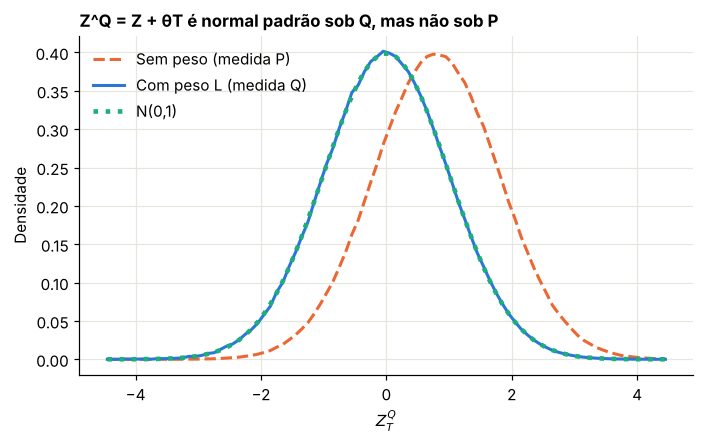

,Grandeza,Simulado,Teoria
0,E^Q[Z^Q],"0,000","0,000"
1,E^Q[(Z^Q)²],"1,001","1,000"


OK — sob Q, Z^Q tem média 0 e variância 1


,θ√T,ESS/n simulado,Teoria e^(−θ²T)
0,"0,200","0,961","0,961"
1,"0,500","0,779","0,779"
2,"1,000","0,366","0,368"
3,"2,000","0,018","0,018"
4,"3,000","0,000","0,000"


OK — o tamanho efetivo da amostra segue e^(−θ²T)


In [11]:
rng = np.random.default_rng(513)
n = 2_000_000
Z_P = rng.standard_normal(n)
L_ = np.exp(-theta * Z_P - 0.5 * theta**2)
Z_Q = Z_P + theta

bins = np.linspace(-4.5, 4.5, 91)
h_sem, _ = np.histogram(Z_Q, bins=bins, density=True)
h_com, _ = np.histogram(Z_Q, bins=bins, weights=L_, density=True)
meio = 0.5 * (bins[1:] + bins[:-1])

fig, ax = plt.subplots()
ax.plot(meio, h_sem, color=LARANJA, ls="--", label="Sem peso (medida P)")
ax.plot(meio, h_com, color=AZUL, label="Com peso L (medida Q)")
ax.plot(meio, norm.pdf(meio), color=VERDE, ls=":", lw=3, label="N(0,1)")
ax.set_title("Z^Q = Z + θT é normal padrão sob Q, mas não sob P")
ax.set_xlabel("$Z^Q_T$")
ax.set_ylabel("Densidade")
ax.legend()
plt.show()

m1 = float(np.mean(L_ * Z_Q))
m2 = float(np.mean(L_ * Z_Q**2))
tabela(pd.DataFrame([
    {"Grandeza": "E^Q[Z^Q]", "Simulado": m1, "Teoria": 0.0},
    {"Grandeza": "E^Q[(Z^Q)²]", "Simulado": m2, "Teoria": 1.0},
]))
ok(abs(m1) < 0.005 and abs(m2 - 1) < 0.01, "sob Q, Z^Q tem média 0 e variância 1")

linhas = []
for th in [0.2, 0.5, 1.0, 2.0, 3.0]:
    L2 = np.exp(-th * Z_P - 0.5 * th**2)
    ess = float(L2.sum() ** 2 / (n * (L2**2).sum()))
    linhas.append({"θ√T": th, "ESS/n simulado": ess, "Teoria e^(−θ²T)": float(np.exp(-th**2))})
e_ = pd.DataFrame(linhas)
tabela(e_)
ok(np.allclose(e_["ESS/n simulado"].iloc[:4], e_["Teoria e^(−θ²T)"].iloc[:4], atol=0.01), "o tamanho efetivo da amostra segue e^(−θ²T)")

### 6.4 Aplicação ao mercado: o preço de mercado do risco

Sob $P$: $\ dS = \mu S\,dt + \sigma S\,dZ$. Definimos

$$\theta = \frac{\mu - r}{\sigma},$$

o **preço de mercado do risco**: o excesso de retorno por unidade de volatilidade. Substituindo $dZ = dZ^Q - \theta\,dt$:

$$dS = \mu S\,dt + \sigma S\,(dZ^Q - \theta\,dt) = (\mu - \sigma\theta)S\,dt + \sigma S\,dZ^Q = rS\,dt + \sigma S\,dZ^Q.$$

Pronto: sob $Q$, o drift é $r$. Falta conferir que o preço descontado é martingale. Pela regra do produto, com $\beta_t = e^{-rt}$ e $d\beta = -r\beta\,dt$:

$$d(\beta S) = \beta\,dS - r\beta S\,dt = \sigma\,\beta S\,dZ^Q.$$

Não há termo em $dt$, logo é um martingale. **E $\mu$ desapareceu.** O mesmo resultado dos Módulos 1 e 3, agora em tempo contínuo.

### 6.5 Fórmula de precificação

Para um direito atingível, as equações (4.2) e (4.3) do livro dão

$$V_0 = \mathbb{E}^Q[\beta_T A_T], \qquad V_t = \beta_t^{-1}\,\mathbb{E}^Q_t[\beta_T A_T].$$

O argumento do livro é igual ao do Módulo 3: $V_T = V_0 + \int\phi\,dS$, e a esperança da integral é zero.

> **Observação sobre o livro.** A passagem que justifica (4.1) afirma que a integral tem esperança zero "pela propriedade de martingale de $S$". Isso exige mais: como vimos na Seção 3.4, a integral de um integrando admissível é, em geral, apenas um martingale local, o que dá $\mathbb{E}^Q[V_T] \le V_0$. A igualdade vale quando $V$ é um martingale verdadeiro, condição que se impõe às estratégias de replicação.

### Laboratório 6.3 — Quatro formas de precificar uma call

Parâmetros: $S_0 = 100$, $K = 105$, $T = 1$, $r = 3\%$, $\mu = 12\%$, $\sigma = 20\%$.

In [12]:
S0, K, T, r, mu, sigma = 100.0, 105.0, 1.0, 0.03, 0.12, 0.20
theta = (mu - r) / sigma
rng = np.random.default_rng(514)
n = 2_000_000
Z_ = np.sqrt(T) * rng.standard_normal(n)
fator = np.exp(-r * T)

ST_P = S0 * np.exp((mu - 0.5 * sigma**2) * T + sigma * Z_)
ST_Q = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * Z_)
L_T = np.exp(-theta * Z_ - 0.5 * theta**2 * T)
pay_P = fator * np.maximum(ST_P - K, 0)
pay_Q = fator * np.maximum(ST_Q - K, 0)
pay_L = pay_P * L_T

referencia = float(bsm_call(S0, K, T, r, sigma))
linhas = []
for nome, a in [("Simular sob Q", pay_Q), ("Simular sob P e ponderar por L", pay_L), ("Simular sob P sem ponderar (errado)", pay_P)]:
    linhas.append({"Método": nome, "Valor": float(a.mean()), "Erro-padrão": float(a.std(ddof=1) / np.sqrt(n)), "Distância em erros-padrão": float((a.mean() - referencia) / (a.std(ddof=1) / np.sqrt(n)))})
linhas.append({"Método": "Fórmula BSM", "Valor": referencia, "Erro-padrão": 0.0, "Distância em erros-padrão": 0.0})
pr = pd.DataFrame(linhas).set_index("Método")
tabela(pr.reset_index())
print("θ =", f3(theta), "| E^Q[βS_T] por peso:", f3(float(np.mean(fator * ST_P * L_T))), "| E^P[βS_T]:", f3(float(np.mean(fator * ST_P))))

ok(abs(pr.loc["Simular sob Q", "Distância em erros-padrão"]) < 4, "simular sob Q reproduz BSM")
ok(abs(pr.loc["Simular sob P e ponderar por L", "Distância em erros-padrão"]) < 4, "simular sob P com peso de Radon-Nikodym reproduz BSM")
ok(abs(pr.loc["Simular sob P sem ponderar (errado)", "Distância em erros-padrão"]) > 20, "a média sob P, sem peso, não é o preço")
ok(abs(np.mean(fator * ST_P * L_T) - S0) < 0.05, "o preço descontado é martingale sob Q")

,Método,Valor,Erro-padrão,Distância em erros-padrão
0,Simular sob Q,"7,125","0,009","-0,371"
1,Simular sob P e ponderar por L,"7,127","0,005","-0,231"
2,Simular sob P sem ponderar (errado),"12,699","0,012","469,697"
3,Fórmula BSM,"7,128","0,000","0,000"


θ = 0,450 | E^Q[βS_T] por peso: 100,008 | E^P[βS_T]: 109,413
OK — simular sob Q reproduz BSM
OK — simular sob P com peso de Radon-Nikodym reproduz BSM
OK — a média sob P, sem peso, não é o preço
OK — o preço descontado é martingale sob Q


---
## 7. O Teorema Fundamental e a completude em tempo contínuo

**Livro: §4.5, teoremas 2 e 3, Proposição 4**

### 7.1 NA não basta: NFLVR

Em tempo contínuo, "não há arbitragem" (NA) não é suficiente para garantir uma medida martingale. Pode haver uma sequência de estratégias que, no limite, gera lucro sem risco, sem que nenhuma seja, individualmente, arbitragem. Delbaen e Schachermayer (1994) estabeleceram a condição certa, **NFLVR** (*no free lunch with vanishing risk*): nenhuma sequência de estratégias admissíveis aproxima um almoço grátis com risco que tende a zero.

| Mundo discreto (Módulo 3) | Mundo contínuo |
|---|---|
| soma $\sum\phi_t\Delta S_t$ | integral de Itô $\int\phi\,dS$ |
| $\phi$ previsível | $\phi$ previsível e admissível |
| qualquer processo adaptado | semimartingale |
| não arbitragem (NA) | NFLVR |
| medida martingale | medida martingale **local** em geral |
| $L = Q/P$ | densidade de Radon-Nikodym, Girsanov |

> **Imprecisão do livro.** O Teorema 3 afirma a existência de uma medida **martingale** para semimartingales em geral. O teorema de Delbaen e Schachermayer (1994) vale nessa forma para $S$ limitado; para $S$ localmente limitado, a medida é martingale **local**; no caso totalmente geral, é sigma-martingale (1998).

### 7.2 Completude: conte as fontes de risco

A regra prática: mercado completo $\Leftrightarrow$ tantos ativos arriscados negociados quantas fontes independentes de risco.

Em Girsanov, cada browniano precisa de seu $\theta$. Cada ativo negociado impõe uma equação $\theta = (\mu - r)/\sigma$. Sobrando browniano sem equação, $\theta$ fica livre.

| Modelo | Fontes de risco | Ativos arriscados | Medida $Q$ |
|---|---|---|---|
| BSM | 1 browniano | 1 | Única |
| Merton (1976) | 1 browniano + saltos | 1 | Infinitas |
| Heston (1993) | 2 brownianos | 1 | Infinitas (preço do risco de volatilidade livre) |
| BCC97 | 3 brownianos + saltos | 1 | Infinitas |

É o mesmo cenário do mercado trinomial do Módulo 3: os preços das opções negociadas selecionam a medida. Por isso, a calibração é o tema central da terceira parte do curso.

### Laboratório 7.1 — Em Heston, várias medidas martingale e vários preços

Sob uma mudança de medida no segundo browniano com preço de risco proporcional à raiz da variância, os parâmetros da variância passam a ser $\kappa^* = \kappa + \lambda$ e $\theta^* = \kappa\theta/(\kappa+\lambda)$. **Toda escolha de $\lambda$ mantém o preço descontado como martingale**, mas muda o preço da opção.

In [13]:
def heston_terminal(S0, r, v0, kappa, theta_v, nu, rho, T, passos, paths, rng):
    """Euler com truncamento total, guardando apenas o valor terminal."""
    dt = T / passos
    v = np.full(paths, v0)
    x = np.zeros(paths)
    for _ in range(passos):
        z1 = rng.standard_normal(paths)
        z2 = rho * z1 + np.sqrt(1 - rho**2) * rng.standard_normal(paths)
        vp = np.maximum(v, 0)
        x += (r - 0.5 * vp) * dt + np.sqrt(vp * dt) * z1
        v += kappa * (theta_v - vp) * dt + nu * np.sqrt(vp * dt) * z2
    return S0 * np.exp(x)


S0, K, T, r = 100.0, 100.0, 1.0, 0.03
v0, kappa, theta_v, nu, rho = 0.04, 2.0, 0.04, 0.4, -0.6
rng = np.random.default_rng(515)
paths = 300_000
linhas = []
for lam in [-1.0, 0.0, 1.0, 3.0]:
    ks = kappa + lam
    ts = kappa * theta_v / ks
    S_ = heston_terminal(S0, r, v0, ks, ts, nu, rho, T, 200, paths, rng)
    desc = np.exp(-r * T)
    m_s = desc * S_
    c_ = desc * np.maximum(S_ - K, 0)
    linhas.append({"λ": lam, "κ*": ks, "θ*": ts, "E^Q[βS_T]": float(m_s.mean()), "Erro-padrão": float(m_s.std(ddof=1) / np.sqrt(paths)), "Call ATM": float(c_.mean()), "Erro-padrão da call": float(c_.std(ddof=1) / np.sqrt(paths))})
h = pd.DataFrame(linhas)
tabela(h)
ok(((h["E^Q[βS_T]"] - S0).abs() < 4 * h["Erro-padrão"] + 0.02).all(), "todas as medidas mantêm o preço descontado como martingale")
ok(h["Call ATM"].max() - h["Call ATM"].min() > 10 * h["Erro-padrão da call"].max(), "o preço da call muda com a medida: mercado incompleto")

,λ,κ*,θ*,E^Q[βS_T],Erro-padrão,Call ATM,Erro-padrão da call
0,"-1,000","1,000","0,080","100,008","0,040","10,269","0,024"
1,"0,000","2,000","0,040","100,001","0,035","9,098","0,021"
2,"1,000","3,000","0,027","100,009","0,031","8,293","0,019"
3,"3,000","5,000","0,016","99,979","0,025","7,165","0,016"


OK — todas as medidas mantêm o preço descontado como martingale
OK — o preço da call muda com a medida: mercado incompleto


---
## 8. Síntese

- O movimento de duração $\Delta t$ tem tamanho $\sqrt{\Delta t}$. Daí vêm a variação total infinita e $(dZ)^2 = dt$.
- A integral de Itô usa o ponto esquerdo, porque corresponde a uma posição decidida antes do movimento.
- O lema de Itô é Taylor com um termo a mais, e é ele que gera o $-\tfrac12\sigma^2$.
- Sem restrição de crédito, estratégias de dobrar geram ganho certo em tempo contínuo; admissibilidade resolve o problema.
- Saltos entram no drift via compensação $\lambda\bar\kappa$.
- Girsanov muda o drift e não muda a volatilidade.
- $\mu$ desaparece: sob $Q$, o drift é $r$.
- Contando fontes de risco e ativos sabemos se $Q$ é única; quando não é, os preços das opções a selecionam.

## 9. Notas sobre o livro neste trecho

| Local | Comentário |
|---|---|
| Justificativa de (4.1) | a esperança da integral é zero só se $V$ for martingale verdadeiro; admissibilidade garante apenas $\mathbb{E}^Q[V_T] \le V_0$ |
| Teorema 3 | a medida é martingale local (sigma-martingale, no caso mais geral), e não martingale, para $S$ não limitado |
| Def. 37 (arbitragem contínua) | exige $V_T \ge 0$, corrigindo a Def. 25 do caso discreto |
| Geral | o teorema de Girsanov não é tratado; o livro passa direto à dinâmica sob $Q$ |

## 10. Exercícios

**Exercício 1.** Use o lema de Itô em $f = Z^3$ para expressar $\int_0^T Z^2\,dZ$.

<details><summary>Solução</summary>

$d(Z^3) = 3Z^2\,dZ + 3Z\,dt$. Logo, $\int_0^T Z^2\,dZ = \tfrac13 Z_T^3 - \int_0^T Z_s\,ds$.
</details>

**Exercício 2.** Para o browniano geométrico, use Itô em $f = S^2$ e obtenha $\mathbb{E}[S_T^2]$.

<details><summary>Solução</summary>

$d(S^2) = 2S\,dS + (dS)^2 = (2\mu + \sigma^2)S^2\,dt + 2\sigma S^2\,dZ$. Tomando esperanças e resolvendo a equação ordinária: $\mathbb{E}[S_T^2] = S_0^2\,e^{(2\mu+\sigma^2)T}$.
</details>

**Exercício 3.** Mostre que $E_t = \exp(\theta Z_t - \tfrac12\theta^2 t)$ satisfaz $dE = \theta E\,dZ$.

<details><summary>Solução</summary>

Com $f(z,t) = e^{\theta z - \theta^2 t/2}$: $f_t = -\tfrac12\theta^2 f$, $f_z = \theta f$, $f_{zz} = \theta^2 f$. Itô dá $df = (-\tfrac12\theta^2 + \tfrac12\theta^2) f\,dt + \theta f\,dZ = \theta f\,dZ$.
</details>

**Exercício 4.** Mostre que $\text{Var}^P(L_T) = e^{\theta^2 T} - 1$.

<details><summary>Solução</summary>

$\mathbb{E}[L_T^2] = \mathbb{E}[e^{-2\theta Z_T - \theta^2 T}] = e^{-\theta^2T}\,e^{2\theta^2T} = e^{\theta^2T}$. Como $\mathbb{E}[L_T] = 1$, a variância é $e^{\theta^2T} - 1$.
</details>

**Exercício 5.** Por que a volatilidade estimada com dados reais pode ser usada, em princípio, sob $Q$, mas o retorno médio não?

<details><summary>Solução</summary>

Girsanov troca o drift e preserva a volatilidade: a variação quadrática é uma propriedade das trajetórias, igual sob medidas equivalentes. O drift, ao contrário, é substituído por $r$. No BSM, isso permite usar $\sigma$ histórico; na prática, a volatilidade futura difere da passada, e o mercado cobra prêmio de risco de variância.
</details>

In [14]:
print(f"Módulo 4 concluído: {_checks['n']} verificações aprovadas.")

Módulo 4 concluído: 34 verificações aprovadas.
